# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

## Phase 3 – Do the parser's errors reach the selection? (RQ1)

Phase 2 (`data_audit_and_protocol`, section 2) fixed the outcome: a candidate is selected for a job if they are in the top half of the
job's candidates, ranked by score, with ties drawn at random. Here we compare the selection made with the parser's
profile (O) and with the corrected one (C), group by group:

* **3.1** What does the correction change, and for which groups?
* **3.2** Independence: are all groups selected at the same rate?
* **3.3** Separation: does the parser make the same errors (false negatives, false positives) in every group?
* **3.4** Sufficiency: given the parser's decision, is a candidate confirmed by the corrected profile at the same rate
  in every group?
* **3.5** Does the answer hold for a stricter selection, the top 3?
* **3.6** Why the South: are southern pairs closer to the cut, why, and what does it mean for a mitigation?

The groups are the values of the sensitive attributes `Gender`, `Location` and their intersection `group`. Each group
is compared with a reference group, which plays the role of the privileged group in the metrics: `Male`, `NORTH` and
`Male_NORTH`. Adecco's score appears only in 3.2, as the real system: it was computed on the profile P, partly entered
by hand (phase 1, section 1.4), so it cannot show the effect of the parser.

All shares in the tables are percentages.

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

In [ ]:
from hiring_cv_bias.fairness.protocol import (
    SCORES,
    add_outcomes,
    filter_protocol,
    load_pairs,
)

df = add_outcomes(filter_protocol(load_pairs()), SCORES)
print(f"protocol pairs: {df.height:,}, candidates: {df['CANDIDATE_ID'].n_unique():,}")

protocol pairs: 36,760, candidates: 6,510


### 3.1 What the correction changes

We follow the correction in three steps: the candidates, their pairs, and the pairs whose outcome changes.

**Candidates.** For each field read by the parser (licenses, languages, job titles in `experience`), the table counts
the candidates who get at least one item the parser had missed, their share of the 6,510 protocol candidates, and the
total number of items added.

In [ ]:
from hiring_cv_bias.config import profile_path
from hiring_cv_bias.fairness.metrics import for_display, profile_corrections

profiles = {v: pl.read_parquet(profile_path(v)) for v in ("O", "C")}
corrections = profile_corrections(
    profiles["O"], profiles["C"], df["CANDIDATE_ID"].unique()
)
display(for_display(corrections))

field,candidates_corrected,share_of_candidates,items_added
"""licenses""",2174,33.4,2174
"""languages""",2675,41.1,4833
"""experience""",3066,47.1,4830


Job titles are corrected for the most candidates, then languages and licenses. Each field is corrected for a large
minority, between a third and a half of the protocol candidates. A corrected candidate gets exactly one license, but
more than one language or title on average.

**Pairs.** A candidate has one pair per job. For each group, the table gives the share of its pairs where the
correction changes `Card_match`, `Languages_match`, the estimated `Experience` (by more than 0.01) and the score.

In [ ]:
from hiring_cv_bias.fairness.metrics import parser_changes

display(for_display(parser_changes(df)))

attribute,group,pairs,Card_match,Languages_match,Experience,score
"""Gender""","""Female""",17489,9.1,6.8,10.3,25.4
"""Gender""","""Male""",19271,9.4,6.5,13.0,27.5
"""Location""","""NORTH""",29144,9.7,6.6,11.3,26.5
"""Location""","""CENTER""",3300,8.6,7.3,12.4,27.2
"""Location""","""SOUTH""",4316,6.8,6.4,14.0,26.0
"""group""","""Female_NORTH""",13798,9.6,7.2,10.4,25.9
"""group""","""Male_NORTH""",15346,9.8,6.1,12.2,27.1
"""group""","""Female_CENTER""",1669,7.5,5.6,8.9,23.1
"""group""","""Male_CENTER""",1631,9.6,9.0,16.0,31.5
"""group""","""Female_SOUTH""",2022,7.0,5.6,11.4,24.4


A license or a language counts only when the job asks for it (phase 1, section 1.2), so `Card_match` and
`Languages_match` change in less than one pair in ten, in every group. The score changes in about one pair in four in
every group, and no group stands out. The South has a little fewer `Card_match` changes than the North and a little
more `Experience` changes. This table has no intervals: whether such differences reach the selection is measured in
3.2 and 3.3.

**Pairs that change outcome.** Now we keep only the pairs whose outcome changes from O to C (`changed_pairs`). The
columns are the same as above, but each share is among these pairs (a pair can have more than one change). `other` is
the share whose score changes only through an `Experience` move of 0.01 or less, and `score_unchanged` the share whose
own score does not change at all.

In [ ]:
from hiring_cv_bias.fairness.metrics import SCORE_CHANGED, outcome_change_sources

display(for_display(outcome_change_sources(df)))
changed = df.filter(pl.col("top_half_O") != pl.col("top_half_C"))
same_score = changed.filter(~SCORE_CHANGED)
print(
    f"pairs whose outcome changes: {changed.height:,} of {df.height:,} "
    f"({changed.height / df.height:.1%})"
)
print(
    f"  with the same score: {same_score.height:,} "
    f"({same_score['top_half_C'].sum()} enter the top half, "
    f"{(~same_score['top_half_C']).sum():,} leave it)"
)
print(f"pairs whose score goes down with C: {(df['score_C'] < df['score_O']).sum()}")

attribute,group,changed_pairs,Card_match,Languages_match,Experience,other,score_unchanged
"""Gender""","""Female""",1374,19.3,11.6,32.5,2.1,45.3
"""Gender""","""Male""",1654,17.1,9.4,39.4,2.2,43.3
"""Location""","""NORTH""",2284,19.0,10.6,35.9,2.1,44.1
"""Location""","""CENTER""",287,13.2,13.6,40.8,2.8,42.5
"""Location""","""SOUTH""",457,16.6,7.7,35.7,2.2,45.7
"""group""","""Female_NORTH""",1038,20.8,12.4,31.9,1.6,44.3
"""group""","""Male_NORTH""",1246,17.5,9.0,39.2,2.4,44.0
"""group""","""Female_CENTER""",108,10.2,14.8,38.9,5.6,45.4
"""group""","""Male_CENTER""",179,15.1,12.8,41.9,1.1,40.8
"""group""","""Female_SOUTH""",228,16.7,6.1,32.5,2.6,49.6


pairs whose outcome changes: 3,028 of 36,760 (8.2%)
  with the same score: 1,339 (0 enter the top half, 1,339 leave it)
pairs whose score goes down with C: 0


The correction changes the outcome of less than one pair in ten (printed under the table). In every group the most
common cause is a new job title (`Experience`), then a license and a language. A few pairs (`other`) move only through
an `Experience` change smaller than 0.01: a shift of the score of a few hundredths is enough to pass a competitor with
the same, or almost the same, score.

Four of these pairs in ten change nothing of their own: they keep the same score (`score_unchanged`). The correction
only adds information, so no score goes down, and all of these pairs leave the top half. They are candidates overtaken
by a competitor of the same job whose CV was corrected: with O they had a place only because the parser had missed
something in that competitor's CV.

### 3.2 Independence: selection rates per group

Independence (statistical parity) asks the selection rate $P(D = 1 \mid A = a)$ to be the same in every group $a$,
where $D = 1$ means selected and $A$ is the sensitive attribute. For each score we compare every group with its reference group in
two ways:

* `spd_<score>`, the statistical parity difference, $\text{SPD} = P(D = 1 \mid A = a) - P(D = 1 \mid A = \text{ref})$:
  the group's rate minus the reference rate (0 means parity);
* `di_<score>`, the disparate impact, $\text{DI} = P(D = 1 \mid A = a) \,/\, P(D = 1 \mid A = \text{ref})$: the group's
  rate divided by the reference rate (1 means parity).

Rates are computed over pairs, the unit fixed in phase 2: each pair is one decision, so a candidate who appears in
several jobs counts once for each job.

**Intervals.** A group has a few hundred to a few thousand candidates, so its numbers are uncertain. We measure this
with a bootstrap: 1,000 times, we draw the candidates again with replacement (a candidate drawn twice counts twice),
draw the ties again and recompute every number. The 95% interval holds the middle 95% of the 1,000 values. We draw
candidates, not pairs: the pairs of a candidate share the same profile and group, so they are not independent, and
drawing them one by one would count them as separate evidence and make the intervals too narrow. If the interval of an
SPD contains 0, or the interval of a DI contains 1, the data show no difference.

The figure shows the rates with their intervals; the dashed line is the rate of all pairs. SPD, in percentage points,
and DI, a ratio, are in the tables with their intervals.

In [ ]:
from hiring_cv_bias.fairness.metrics import bootstrap, parser_effect, selection_rates

results = bootstrap(
    df,
    {
        "rates": selection_rates,
        "effect": parser_effect,
        "effect_top3": lambda d: parser_effect(d, outcome="top3"),
    },
)

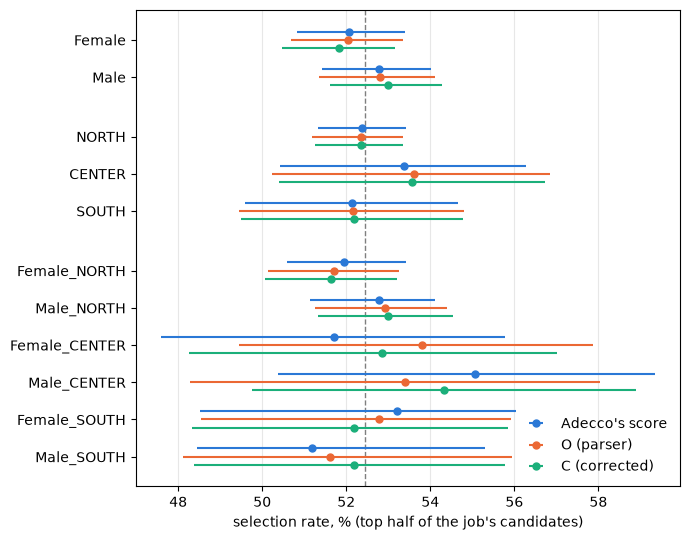

In [ ]:
from hiring_cv_bias.fairness.plots import plot_selection_rates

rates = results["rates"]
plot_selection_rates(rates, overall=df["top_half_O"].mean())
plt.show()

In [ ]:
from hiring_cv_bias.fairness.protocol import COMPARED_VERSIONS

display(for_display(rates, [f"rate_{v}" for v in COMPARED_VERSIONS]))
display(
    for_display(
        rates,
        [f"spd_{v}" for v in COMPARED_VERSIONS],
        ratios=[f"di_{v}" for v in COMPARED_VERSIONS],
    )
)

attribute,group,pairs,rate_adecco,rate_O,rate_C
"""Gender""","""Female""",17489,"""52.1 [50.8, 53.4]""","""52.0 [50.7, 53.3]""","""51.8 [50.5, 53.1]"""
"""Gender""","""Male""",19271,"""52.8 [51.4, 54.0]""","""52.8 [51.4, 54.1]""","""53.0 [51.6, 54.3]"""
"""Location""","""NORTH""",29144,"""52.4 [51.3, 53.4]""","""52.4 [51.2, 53.3]""","""52.4 [51.3, 53.3]"""
"""Location""","""CENTER""",3300,"""53.4 [50.4, 56.3]""","""53.6 [50.2, 56.8]""","""53.6 [50.4, 56.7]"""
"""Location""","""SOUTH""",4316,"""52.1 [49.6, 54.7]""","""52.2 [49.4, 54.8]""","""52.2 [49.5, 54.8]"""
"""group""","""Female_NORTH""",13798,"""51.9 [50.6, 53.4]""","""51.7 [50.1, 53.3]""","""51.6 [50.1, 53.2]"""
"""group""","""Male_NORTH""",15346,"""52.8 [51.1, 54.1]""","""52.9 [51.3, 54.4]""","""53.0 [51.3, 54.5]"""
"""group""","""Female_CENTER""",1669,"""51.7 [47.6, 55.8]""","""53.8 [49.5, 57.9]""","""52.8 [48.3, 57.0]"""
"""group""","""Male_CENTER""",1631,"""55.1 [50.4, 59.4]""","""53.4 [48.3, 58.0]""","""54.3 [49.8, 58.9]"""
"""group""","""Female_SOUTH""",2022,"""53.2 [48.5, 56.0]""","""52.8 [48.6, 55.9]""","""52.2 [48.3, 55.9]"""


attribute,group,pairs,spd_adecco,spd_O,spd_C,di_adecco,di_O,di_C
"""Gender""","""Female""",17489,"""-0.7 [-2.6, 1.2]""","""-0.8 [-2.8, 1.1]""","""-1.2 [-3.2, 0.8]""","""0.99 [0.95, 1.02]""","""0.99 [0.95, 1.02]""","""0.98 [0.94, 1.02]"""
"""Gender""","""Male""",19271,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]"""
"""Location""","""NORTH""",29144,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]"""
"""Location""","""CENTER""",3300,"""1.0 [-2.0, 4.2]""","""1.3 [-2.3, 4.7]""","""1.2 [-2.1, 4.5]""","""1.02 [0.96, 1.08]""","""1.02 [0.96, 1.09]""","""1.02 [0.96, 1.09]"""
"""Location""","""SOUTH""",4316,"""-0.2 [-2.9, 2.5]""","""-0.2 [-3.1, 2.8]""","""-0.2 [-3.1, 2.7]""","""1.00 [0.94, 1.05]""","""1.00 [0.94, 1.05]""","""1.00 [0.94, 1.05]"""
"""group""","""Female_NORTH""",13798,"""-0.8 [-2.7, 1.4]""","""-1.2 [-3.4, 1.1]""","""-1.3 [-3.6, 0.8]""","""0.98 [0.95, 1.03]""","""0.98 [0.94, 1.02]""","""0.97 [0.93, 1.02]"""
"""group""","""Male_NORTH""",15346,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]"""
"""group""","""Female_CENTER""",1669,"""-1.1 [-5.2, 3.5]""","""0.9 [-3.8, 5.5]""","""-0.1 [-4.8, 4.3]""","""0.98 [0.90, 1.07]""","""1.02 [0.93, 1.11]""","""1.00 [0.91, 1.08]"""
"""group""","""Male_CENTER""",1631,"""2.3 [-2.6, 6.9]""","""0.5 [-4.5, 5.4]""","""1.3 [-3.6, 6.0]""","""1.04 [0.95, 1.12]""","""1.01 [0.91, 1.10]""","""1.03 [0.93, 1.11]"""
"""group""","""Female_SOUTH""",2022,"""0.4 [-4.1, 3.5]""","""-0.1 [-4.6, 3.3]""","""-0.8 [-4.9, 3.1]""","""1.01 [0.92, 1.07]""","""1.00 [0.91, 1.06]""","""0.98 [0.91, 1.06]"""


Every SPD is within a couple of points of 0, and every DI within a few hundredths of 1, with Adecco's score, with O
and with C. Every SPD interval contains 0 and every DI interval contains 1. Women are selected a little less often
than men with every score, but well inside the interval. The lowest bound of any DI is far above the 0.8 of the
four-fifths rule. The data show no violation of independence, before or after the correction.

### 3.3 Separation: the parser's errors per group

To measure the parser's errors, we take the outcome with the corrected profile as the label $Y$, and the outcome with
the parser's profile as the decision $D$. C is not the truth: it holds what our extractors recovered from the CV text.
So the errors below are errors of O relative to C.

* **False negative** ($D = 0$, $Y = 1$): a pair selected with C that O leaves out, `fnr` $= P(D = 0 \mid Y = 1, A = a)$.
* **False positive** ($D = 1$, $Y = 0$): a pair that O selects and C does not, `fpr` $= P(D = 1 \mid Y = 0, A = a)$.

Separation (equalized odds) asks both rates to be the same in every group. `fnr_diff` and `fpr_diff` are the gaps from
the reference group. `rate_change`, the rate with C minus the rate with O, tells whether a group gains places when the
parser is corrected. Every job selects the same number of candidates with O and with C, so a group can have
`rate_change` $= 0$ and still many errors, if it has as many false negatives as false positives. The figure shows
`rate_change` and the two gaps; the dashed line is 0.

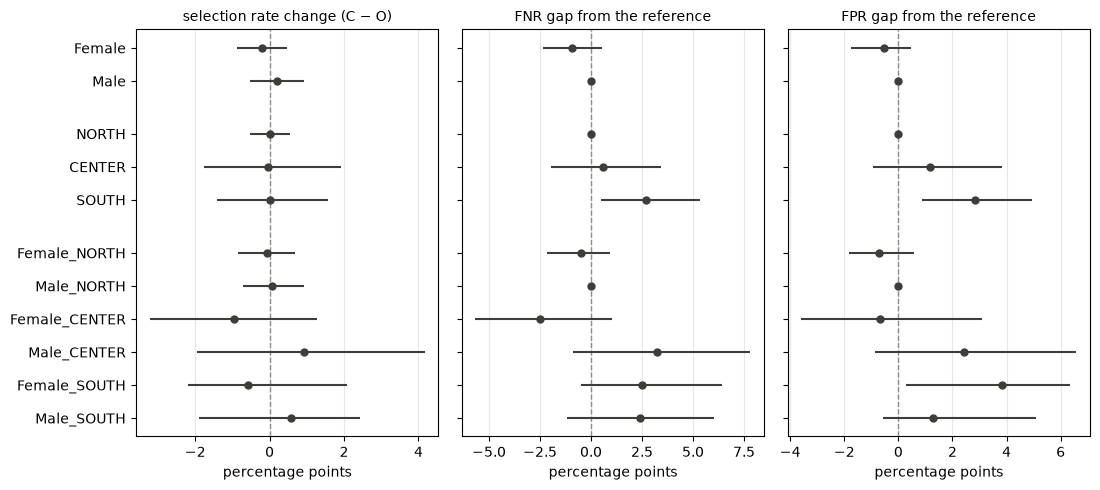

In [ ]:
from hiring_cv_bias.fairness.plots import plot_parser_effect

effect = results["effect"]
plot_parser_effect(effect)
plt.show()

In [ ]:
display(for_display(effect, ["rate_change", "fnr", "fpr", "fnr_diff", "fpr_diff"]))

attribute,group,pairs,rate_change,fnr,fpr,fnr_diff,fpr_diff
"""Gender""","""Female""",17489,"""-0.2 [-0.9, 0.5]""","""7.4 [6.3, 8.4]""","""8.4 [7.5, 9.1]""","""-0.9 [-2.4, 0.5]""","""-0.5 [-1.7, 0.5]"""
"""Gender""","""Male""",19271,"""0.2 [-0.5, 0.9]""","""8.3 [7.1, 9.3]""","""8.9 [8.1, 9.7]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.6]""","""7.5 [6.7, 8.3]""","""8.2 [7.6, 8.8]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.8, 1.9]""","""8.1 [5.7, 10.9]""","""9.4 [7.4, 11.8]""","""0.6 [-2.0, 3.4]""","""1.2 [-0.9, 3.8]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.4, 1.6]""","""10.2 [8.1, 12.7]""","""11.0 [9.1, 13.1]""","""2.7 [0.5, 5.4]""","""2.8 [0.9, 5.0]"""
"""group""","""Female_NORTH""",13798,"""-0.1 [-0.8, 0.7]""","""7.2 [6.1, 8.3]""","""7.9 [7.0, 8.6]""","""-0.5 [-2.2, 0.9]""","""-0.7 [-1.8, 0.6]"""
"""group""","""Male_NORTH""",15346,"""0.1 [-0.7, 0.9]""","""7.7 [6.5, 9.0]""","""8.6 [7.6, 9.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-1.0 [-3.2, 1.3]""","""5.2 [2.5, 8.7]""","""7.9 [5.1, 11.3]""","""-2.5 [-5.7, 1.0]""","""-0.7 [-3.6, 3.1]"""
"""group""","""Male_CENTER""",1631,"""0.9 [-2.0, 4.2]""","""10.9 [6.9, 15.3]""","""11.0 [7.7, 15.0]""","""3.2 [-0.9, 7.8]""","""2.4 [-0.9, 6.6]"""
"""group""","""Female_SOUTH""",2022,"""-0.6 [-2.2, 2.1]""","""10.2 [7.5, 13.8]""","""12.4 [9.0, 14.7]""","""2.5 [-0.5, 6.4]""","""3.8 [0.3, 6.4]"""


**Places.** Every `rate_change` interval contains 0, and all the point estimates are within about one point of it.
Correcting the parser does not move places from one group to another.

**Errors.** The South is the only area where the parser's errors differ from the North, and in both directions: O
leaves out more of the southern pairs that C selects (FNR), and selects more of the southern pairs that C does not
select (FPR). Each gap is about three points, and both intervals exclude 0. False negatives and false positives cancel
out in the count, so `rate_change` is 0, but more southern decisions are wrong. Among the six intersectional groups,
the only gap whose interval excludes 0 is the FPR of `Female_SOUTH`, of the same size as the South's. So equalized
odds fails for this group too, through the FPR. Between women and men there is no gap.

### 3.4 Sufficiency: how reliable the parser's decision is, per group

Sufficiency (calibration) conditions the other way round: it fixes the decision and asks whether the true outcome
depends on the group. For a binary decision it is two equalities: the positive predictive value `ppv` $= P(Y = 1 \mid D = 1, A = a)$,
the share of the pairs O selects that C confirms, and the negative predictive value `npv` $= P(Y = 0 \mid D = 0, A = a)$,
the share of the pairs O rejects that C confirms. Separation compares the rows of the confusion matrix
(given the true outcome, how the parser decides); sufficiency compares its columns (given the parser's decision, how
often it is right). The figure shows the gaps of the two values from the reference group (`ppv_diff`, `npv_diff`); the
dashed line is 0.

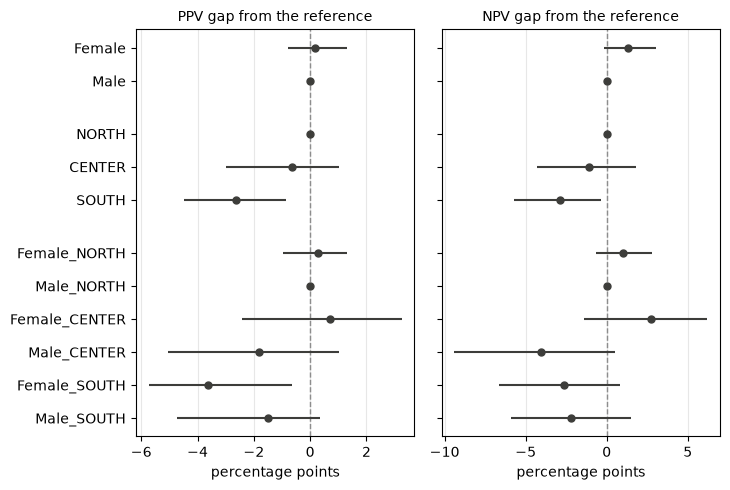

In [ ]:
from hiring_cv_bias.fairness.plots import SUFFICIENCY_PANELS

plot_parser_effect(effect, SUFFICIENCY_PANELS)
plt.show()

In [ ]:
display(for_display(effect, ["ppv", "npv", "ppv_diff", "npv_diff"]))

attribute,group,pairs,ppv,npv,ppv_diff,npv_diff
"""Gender""","""Female""",17489,"""92.2 [91.6, 93.1]""","""92.0 [91.0, 93.1]""","""0.2 [-0.8, 1.3]""","""1.3 [-0.2, 3.0]"""
"""Gender""","""Male""",19271,"""92.1 [91.3, 92.8]""","""90.7 [89.5, 91.9]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""92.5 [92.0, 93.1]""","""91.8 [90.9, 92.7]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""91.9 [89.7, 93.5]""","""90.7 [87.6, 93.4]""","""-0.7 [-3.0, 1.0]""","""-1.1 [-4.3, 1.8]"""
"""Location""","""SOUTH""",4316,"""89.9 [88.1, 91.5]""","""88.9 [86.3, 91.2]""","""-2.6 [-4.5, -0.9]""","""-2.9 [-5.7, -0.4]"""
"""group""","""Female_NORTH""",13798,"""92.7 [91.9, 93.5]""","""92.3 [91.1, 93.5]""","""0.3 [-1.0, 1.3]""","""1.0 [-0.7, 2.8]"""
"""group""","""Male_NORTH""",15346,"""92.4 [91.7, 93.2]""","""91.3 [89.9, 92.6]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""93.1 [90.2, 95.5]""","""94.0 [90.1, 97.0]""","""0.7 [-2.4, 3.3]""","""2.7 [-1.4, 6.2]"""
"""group""","""Male_CENTER""",1631,"""90.6 [87.4, 93.3]""","""87.2 [82.1, 91.7]""","""-1.8 [-5.1, 1.0]""","""-4.1 [-9.4, 0.5]"""
"""group""","""Female_SOUTH""",2022,"""88.8 [86.8, 91.7]""","""88.7 [85.0, 91.8]""","""-3.6 [-5.7, -0.6]""","""-2.6 [-6.6, 0.8]"""


Both predictive values are high in every group: when the parser's profile selects a candidate, the corrected one
confirms it about nine times in ten, and the same for a rejection.

The South is again the only area that differs from the North, and on both sides: its selections and its rejections are
confirmed a few points less often, and both intervals exclude 0. Among the intersectional groups, women from the South
have a lower PPV, with an interval that excludes 0; their NPV gap and every other gap include 0. Between women and men
there is no gap.

So the South passes independence but fails separation and sufficiency: it is selected at the same rate (3.2), but O's
decisions on southern candidates are wrong more often in both directions (3.3) and, seen from the decision's side,
confirmed less often (3.4).

### 3.5 The same with the top 3

A stricter selection: the first three candidates of every job. The table repeats `rate_change`, `fnr_diff` and
`fpr_diff` of 3.3 and `ppv_diff` and `npv_diff` of 3.4, with `top3` as the outcome.

In [ ]:
display(
    for_display(
        results["effect_top3"],
        ["rate_change", "fnr_diff", "fpr_diff", "ppv_diff", "npv_diff"],
    )
)

attribute,group,pairs,rate_change,fnr_diff,fpr_diff,ppv_diff,npv_diff
"""Gender""","""Female""",17489,"""0.3 [-0.3, 0.9]""","""-0.5 [-2.6, 2.0]""","""-0.8 [-1.6, -0.1]""","""2.3 [0.4, 4.0]""","""0.1 [-0.9, 1.0]"""
"""Gender""","""Male""",19271,"""-0.3 [-0.9, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.9, 1.8]""","""1.9 [-2.4, 6.6]""","""2.0 [0.5, 3.9]""","""-1.9 [-5.5, 1.3]""","""-2.0 [-4.2, 0.1]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.3, 1.2]""","""4.4 [0.3, 8.3]""","""0.4 [-0.5, 1.5]""","""-4.5 [-7.8, -1.6]""","""-0.4 [-1.8, 0.9]"""
"""group""","""Female_NORTH""",13798,"""0.3 [-0.3, 1.0]""","""0.4 [-2.1, 2.9]""","""-0.6 [-1.4, 0.2]""","""1.7 [-0.4, 3.6]""","""-0.2 [-1.2, 0.7]"""
"""group""","""Male_NORTH""",15346,"""-0.3 [-0.9, 0.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-0.2 [-2.1, 2.1]""","""-2.2 [-6.7, 3.6]""","""0.1 [-1.7, 2.0]""","""2.5 [-1.3, 6.2]""","""-0.1 [-3.1, 2.0]"""
"""group""","""Male_CENTER""",1631,"""0.2 [-3.2, 3.6]""","""6.4 [-0.6, 13.7]""","""3.3 [0.8, 6.8]""","""-4.7 [-11.3, 0.0]""","""-4.0 [-7.8, -0.9]"""
"""group""","""Female_SOUTH""",2022,"""0.3 [-1.4, 2.2]""","""5.1 [-0.6, 11.3]""","""-0.1 [-1.5, 1.4]""","""-2.9 [-7.8, 1.3]""","""-0.7 [-2.9, 1.2]"""


Every `rate_change` interval still contains 0. The higher FNR of the South remains, and it is larger than with the top
half; its higher FPR does not remain. Three separation gaps exclude 0 here but not in 3.3: a higher FPR in the Center
and for its men, and a slightly lower FPR for women.

For sufficiency, the lower PPV of the South remains, while its NPV gap does not: with three places per job, the pairs
O rejects are almost all confirmed in every group, so the groups differ only on the pairs it selects. Two sufficiency
gaps exclude 0 here but not in 3.4: a lower NPV for men from the Center and a higher PPV for women. The lower PPV of
women from the South seen in 3.4 does not hold here.

**Many comparisons.** 3.3 to 3.5 hold 64 gaps ($8 \text{ groups} \times 4 \text{ rates} \times 2 \text{ outcomes}$). At the 95% level, about three of them
would exclude 0 by chance alone. So a gap seen with only one outcome is weak evidence. The gaps seen with both
outcomes are the higher FNR and the lower PPV of the South.

### 3.6 Why the South: the lists, not the parser

3.3 and 3.4 show that O's decisions on southern pairs are wrong more often, in both directions. But 3.1 shows that the
correction touches southern and northern pairs in the same way: the score changes for about the same share of southern
and northern pairs. So the South does not get more corrections; its corrections flip more outcomes.

**The claim of this section.** An outcome is a place in the job's list. A change of score flips the outcome only if it
is big enough to move the pair across the cut: a pair far from the cut keeps its place, a pair close to the cut loses
it for a small change. Southern pairs are closer to the cut, because many southern jobs require no skill that
separates the candidates. In those lists any noise, not only the parser's, flips more decisions. This is the
robustness side of RQ1: how stable the decisions are under the noise of the profile, group by group.

**One metric.** The whole section uses the error rate: the share of a group's pairs whose outcome differs between O
and C. It counts the false negatives and the false positives of 3.3 together, over all the pairs. The gap is the
South's rate minus the North's. The intervals come from the same bootstrap as 3.2.

#### 3.6.1 Are southern pairs closer to the cut?

The margin of a pair is the distance between its score and the score of the last selected candidate of its list (the
cutoff score). The table gives, per region, the median margin, the share of pairs whose margin is within 0.1, and the share of pairs whose outcome Adecco's own score leaves to the tie-break (`draw_adecco`: a tie across the
cut).

In [ ]:
from hiring_cv_bias.config import REVERSE_MATCHING_PATH
from hiring_cv_bias.fairness.robustness import (
    error_by_class,
    list_class,
    margin_table,
    standardized_error,
)
from hiring_cv_bias.reverse_matching.components import job_requirements
from hiring_cv_bias.utils import load_excel_sheets

jobs_req = job_requirements(load_excel_sheets(REVERSE_MATCHING_PATH, ["Jobs"])["Jobs"])
df = df.join(
    jobs_req.select(
        "Job_id", (pl.col("req_skills").list.len() > 0).alias("skills_required")
    ),
    on="Job_id",
    how="left",
).with_columns(list_class(pl.col("skills_required"), "O").alias("class"))
robust = bootstrap(
    df,
    {
        "standardized": lambda d: standardized_error(d, "Location", "NORTH"),
        "by_class": lambda d: error_by_class(d, pl.col("class")),
    },
)
display(
    for_display(
        margin_table(df, ["Location"], draws=("adecco",)), ratios=["margin_median"]
    )
)

attribute,group,pairs,margin_median,within_0.1,draw_adecco
"""Location""","""NORTH""",29144,0.35,31.5,19.5
"""Location""","""CENTER""",3300,0.3,34.9,21.0
"""Location""","""SOUTH""",4316,0.16,42.6,29.1


Southern pairs are closer to the cut on every measure: their median margin is less than half the North's, a larger
share of them is within 0.1 points of the cut, and Adecco's own score ties about three southern pairs in ten across
the cut, against two in ten in the North. The Center is close to the North.

#### 3.6.2 Would the gap remain if southern pairs were as far from the cut as northern ones?

We split the pairs into five bands of margin: a tie, up to 0.1, 0.1 to 0.3, 0.3 to 0.6, above 0.6. `error_std` takes
the region's error rate in each band and weights it by the share of northern pairs in that band: it is the error rate
the region would have with the North's margins. `gap` and `gap_std` are the gaps of `error` and `error_std` from the
North, and `explained` $= \text{gap} - \text{gap\_std}$ is the part of the gap due to the margins.

In [ ]:
display(
    for_display(
        robust["standardized"].drop(
            "explained_share", "explained_share_lo", "explained_share_hi"
        )
    )
)

attribute,group,pairs,error,error_std,gap,gap_std,explained
"""Location""","""CENTER""",3300,"""8.7 [7.1, 10.5]""","""8.3 [6.6, 10.2]""","""0.9 [-0.8, 2.8]""","""0.5 [-1.2, 2.4]""","""0.4 [0.1, 0.8]"""
"""Location""","""NORTH""",29144,"""7.8 [7.3, 8.3]""","""7.8 [7.3, 8.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""SOUTH""",4316,"""10.6 [9.1, 12.1]""","""9.3 [8.1, 10.8]""","""2.8 [1.3, 4.4]""","""1.5 [0.1, 3.1]""","""1.3 [0.7, 1.8]"""


About half of the gap goes. With the North's margins, the South's error rate moves toward the North's, and
the part of the gap that the margins explain has an interval that does not include 0. So the South's position near the
cut is a cause of its errors.

#### 3.6.3 Why are southern pairs closer to the cut?

The score is a sum of seven terms (phase 1). A term separates the candidates of a list only if it takes different
values inside the list; a term that is the same for everyone in the list moves all of them together and separates
nobody. Which term stops separating the candidates in the South? For every term, the table gives its standard deviation
inside the list, averaged over the pairs of each region. Each term is $\text{weight} \times \text{component}$,
so the values are in points of score: how far a candidate is, on average, from the mean of its list.
`change` is the South's value relative to the North's, in percent; a difference below 0.01 points counts as 0.

In [ ]:
from hiring_cv_bias.fairness.robustness import term_spread

regions = ["NORTH", "CENTER", "SOUTH"]
display(
    for_display(term_spread(df, "O").filter(pl.col("term") != "score"), ratios=regions)
)

term,NORTH,CENTER,SOUTH,change
"""Experience""",0.34,0.3,0.39,13.3
"""Interest""",0.32,0.29,0.25,-20.4
"""Card_match""",0.03,0.03,0.02,0.0
"""Languages_match""",0.02,0.03,0.02,0.0
"""Regulated_Trainings_match""",0.0,0.0,0.0,0.0
"""match_skills""",0.18,0.11,0.07,-61.3
"""Distance_match""",0.24,0.26,0.23,-6.6


`match_skills` is the term that changes most between the regions: its spread inside the list is less than half in the
South compared with the North. `Interest` loses some spread too, `Experience` and `Distance_match` do not, and the
three 0.3-weighted terms separate almost nobody anywhere. The two terms that lose spread in the South, `match_skills`
and `Interest`, are the two that the parser never touches (phase 1, sections 1.2 and 1.4): the parser is not what
compresses the South's lists.

`match_skills` has weight 1 and is the share of the job's required skills that the candidate holds. It reads the
`skills` field of Adecco's profile, which no extractor touches. When the job requires no skill, or requires skills
that give every candidate of the list the same value, `match_skills` cannot separate
the candidates, and the scores pile up near the cut. So we split the lists into three classes:

* `none required`: the job requires no skill;
* `required, same for all`: the job requires skills, but every candidate of the list gets the same `match_skills`;
* `required, discriminate`: the required skills give the candidates different values.

The table counts the lists of each class per region, with the median margin. The figure gives the error rate of the
North and of the South in each class, with its 95% interval, and the gap on the right of each row.

In [ ]:
from hiring_cv_bias.fairness.robustness import list_classes_table

display(
    for_display(
        list_classes_table(df, pl.col("class"), "O"),
        ["share_of_lists"],
        ratios=["margin_median"],
    )
)

Location,class,lists,share_of_lists,pairs,margin_median
"""CENTER""","""none required""",185,53.2,1717,0.25
"""CENTER""","""required, discriminate""",121,34.8,1227,0.38
"""CENTER""","""required, same for all""",42,12.1,356,0.18
"""NORTH""","""none required""",1117,41.9,11197,0.3
"""NORTH""","""required, discriminate""",1181,44.3,14419,0.4
"""NORTH""","""required, same for all""",366,13.7,3528,0.21
"""SOUTH""","""none required""",199,59.9,2653,0.1
"""SOUTH""","""required, discriminate""",83,25.0,1162,0.41
"""SOUTH""","""required, same for all""",50,15.1,501,0.08


The South has more lists where the score cannot separate the candidates. Six southern lists in ten belong to a job
that requires no skill, against four in ten in the North; only a quarter have required skills that separate the
candidates, against almost half in the North. Where the required skills separate the candidates, the margins are the
same in both regions. In the other two classes the South's margins are much smaller.

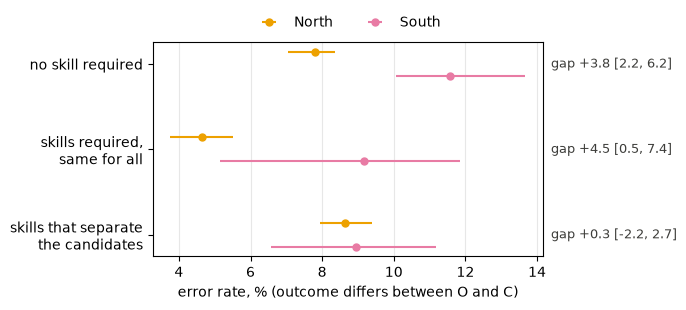

In [ ]:
from hiring_cv_bias.fairness.plots import plot_error_by_class

plot_error_by_class(robust["by_class"])
plt.show()

The gap in error rate between the South and the North appears only where the score cannot separate the candidates,
the first two classes. Where the required skills separate the candidates, the interval of the gap contains 0, so
there the data show no difference between the two regions. Of the first two classes, the stronger result is the first, the jobs that require no skill:
its gap is large and its interval is well above 0. In the second class the gap is as large but the lower bound of its interval is close to 0.

#### 3.6.4 Does any noise do this, or only the parser?

If the gap comes from the lists, the same noise should flip more southern decisions, with no parser involved. We start
from the real profile P, which the parser does not touch, and add Gaussian noise to the estimated `Experience` of
every pair (standard deviation 0.05 or 0.10). We recompute the score with the formula, re-rank every list with the
same tie-break, and count the pairs whose outcome under P changes, averaged over 20 draws. The noise is drawn from the same distribution in every region. The table gives the share of flipped decisions per class, for the
North and the South (`north_0.05` is the North with noise 0.05).

In [ ]:
from hiring_cv_bias.fairness.robustness import LIST_CLASSES, perturbation_flips

flips = (
    perturbation_flips(df, version="P", by=("Location", "class"))
    .filter(pl.col("Location").is_in(["NORTH", "SOUTH"]))
    .with_columns(
        pl.format(
            "{}_{}", pl.col("Location").str.to_lowercase(), pl.col("sigma")
        ).alias("region_noise")
    )
    .pivot(on="region_noise", index="class", values="flipped")
    .sort(
        pl.col("class").replace_strict(
            {c: i for i, c in enumerate(LIST_CLASSES)}, return_dtype=pl.Int64
        )
    )
)
display(for_display(flips))

class,north_0.05,south_0.05,north_0.1,south_0.1
"""none required""",12.3,18.8,15.3,23.1
"""required, same for all""",13.8,22.7,16.8,26.6
"""required, discriminate""",8.4,11.9,10.7,13.9


With both noise levels, southern decisions flip more often than northern ones, in every class. The difference is
largest in the first two classes, where the score cannot separate the candidates: there the South flips 6 to 10 points
more of its decisions than the North. In the third class both regions are more stable and the difference is about half
as large. So the gap is a property of the lists, with no parser involved.

#### 3.6.5 What could a mitigation do?

The bias found in RQ1 is a gap in separation and sufficiency; independence holds. A mitigation could act in two
places:

* *Change the matcher.* There is nothing to train: the matcher is the formula of phase 1, seven known weights and a
  cut in the list. The in-processing methods add a fairness term to a loss that does not exist here.
* *Post-process the decisions.* Equalized odds post-processing ([Hardt et al. 2016](https://papers.neurips.cc/paper_files/paper/2016/file/6a9659feb1216f14f7384ba499518b38-Paper.pdf)) flips decisions at random, with
  probabilities per region: a selected pair stays selected with probability `keep`, a rejected one becomes selected
  with probability `add`. A region with rates $(\text{FPR}, \text{TPR})$, where $\text{TPR} = 1 - \text{FNR}$, ends with

  $$\text{TPR}' = \text{keep} \cdot \text{TPR} + \text{add} \cdot (1 - \text{TPR}),
  \qquad \text{FPR}' = \text{keep} \cdot \text{FPR} + \text{add} \cdot (1 - \text{FPR}),$$

  so it can reach only the rates inside its quadrilateral in the figure below, between $(0, 0)$, its own point
  $(\text{FPR}, \text{TPR})$, $(1, 1)$ and the mirrored point $(1 - \text{FPR}, 1 - \text{TPR})$. Equalized odds needs a
  point inside both quadrilaterals; fairlearn's `ThresholdOptimizer` picks the one with the fewest errors against C,
  searching it on a grid of 1,000 values of FPR. The table gives, per region,
  the rates of O before and after the flips and the two probabilities; the dotted line in the figure is the move of
  the North to the common point.


group,pairs,tpr,fpr,keep,add,tpr_after,fpr_after
"""NORTH""",29144,92.5,8.2,0.97,0.03,89.8,11.1
"""CENTER""",3300,91.9,9.4,0.98,0.02,89.8,11.1
"""SOUTH""",4316,89.8,11.0,1.0,0.0,89.8,11.1


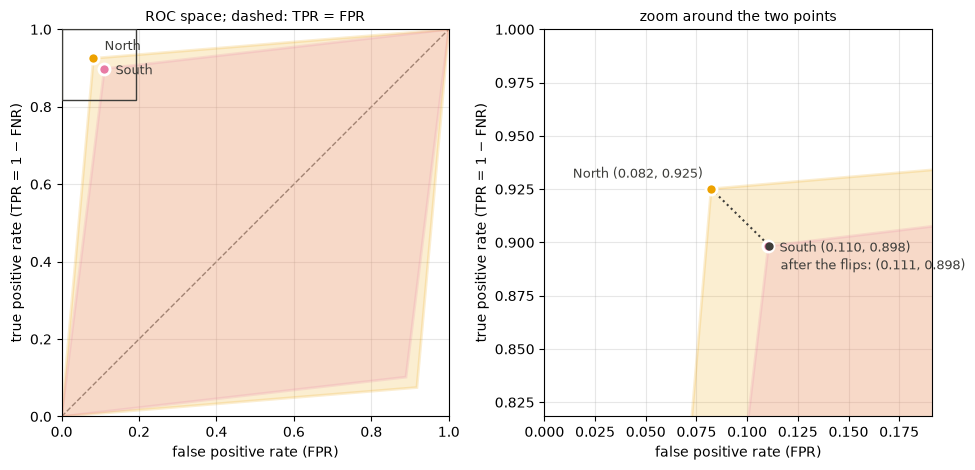

In [ ]:
from hiring_cv_bias.fairness.mitigation import equalized_odds_on_decisions, flip_table
from hiring_cv_bias.fairness.plots import plot_reachable_region

optimizer = equalized_odds_on_decisions(df, "O", label="C", outcome="top_half")
flips = flip_table(optimizer, df, "O", label="C", outcome="top_half")
display(for_display(flips, ratios=["keep", "add"]))
plot_reachable_region(flips)
plt.show()

The South's point lies inside the North's quadrilateral, so the best rates the two regions can share are the
South's own: the optimizer leaves every southern decision as it is (`keep` 1, `add` 0) and brings the North, and the Center with
it, down to the South's rates, by dropping some of their selected pairs and selecting some of their rejected ones. To equalize the errors
this way, no southern decision would get better.


### Findings for RQ1

* **The parser's errors reach the selection.** Correcting them changes the score of about one pair in four, and the
  outcome of less than one in ten. A new job title is the most common cause, and four in ten of the pairs that change
  outcome are candidates overtaken by a corrected competitor (3.1).
* **Independence is not violated.** No group is selected at a different rate from its reference group, with O or with
  C: every SPD interval contains 0 and every DI interval contains 1 (3.2).
* **Separation is violated for the South.** O has a higher false negative
  rate and a higher false positive rate for southern pairs than for northern ones, each by about three points; the
  higher FNR holds with the top 3 too (3.5).
* **Sufficiency is violated for the South too.** Given the parser's decision, a southern pair is confirmed by the
  corrected profile less often than a northern one, for selections and for rejections (3.4); the lower PPV holds with
  the top 3 (3.5).
* **No gender gap.** Women and men have the same error rates and predictive values overall: for each of the four rates (FNR, FPR, PPV, NPV), the gap between Female and Male has an interval that holds 0.
* **Why the South: the lists, not the parser.** The correction touches southern and northern pairs in the same way,
  but southern pairs are closer to the cut: most southern jobs require no skill, or skills that give every candidate
  the same value, so the score cannot separate the candidates and their scores pile up near the cut.
  The term that loses this separating power in the South, `match_skills`, is one the parser never touches. The same
  random noise on `Experience`, with no parser involved, flips more southern decisions, most of all in the lists that cannot separate the candidates.